In [1]:
import gc
import torch

# Clear Python garbage
gc.collect()

# Clear CUDA cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print("GPU memory cleared.")

GPU memory cleared.


In [2]:
if torch.cuda.is_available():
    print(torch.cuda.memory_summary())
else:
    print("CUDA is not available.")

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |      0 B   |
|       from small pool |      0 B   |      0 B   |      0 B   |      0 B   |
|---------------------------------------------------------------------------|
| Active memory         |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |

In [3]:
# ==========================================
# NeurALLNet Version-04
# Environment Setup
# ==========================================
!pip install -q spikingjelly
import spikingjelly
import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from spikingjelly.activation_based import neuron, surrogate, functional

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("NeurALLNet Version-04")
print("======================")
print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

NeurALLNet Version-04
PyTorch: 2.11.0+cu128
CUDA Available: True
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB


In [4]:
import os

print("Kaggle input directories:\n")

for item in os.listdir("/kaggle/input"):
    print(item)

Kaggle input directories:

datasets


In [5]:
import os

DATA_ROOT = "/kaggle/input/datasets"

for root, dirs, files in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:8]:
        print(f"{indent}    {file}")

    if len(files) > 8:
        print(f"{indent}    ... and {len(files)-8} more files")

datasets/
    faiznadeem39/
        milk10k/
            MILK10k_Training_GroundTruth.csv
            MILK10k_Training_Metadata.csv
            MILK10k_Training_Supplement.csv
            MILK10k_Training_Input/


In [6]:
# ==========================================
# Dataset Path Configuration
# ==========================================

DATA_ROOT = "/kaggle/input/datasets/faiznadeem39/milk10k"

GROUND_TRUTH_CSV = os.path.join(
    DATA_ROOT, "MILK10k_Training_GroundTruth.csv"
)

METADATA_CSV = os.path.join(
    DATA_ROOT, "MILK10k_Training_Metadata.csv"
)

IMAGE_ROOT = os.path.join(
    DATA_ROOT,
    "MILK10k_Training_Input",
    "MILK10k_Training_Input"
)

# Verify paths
print("Ground Truth:", os.path.exists(GROUND_TRUTH_CSV))
print("Metadata:", os.path.exists(METADATA_CSV))
print("Image Root:", os.path.exists(IMAGE_ROOT))

print("\nImage directory contents:")
if os.path.exists(IMAGE_ROOT):
    print(os.listdir(IMAGE_ROOT)[:10])

Ground Truth: True
Metadata: True
Image Root: True

Image directory contents:
['IL_0000652', 'IL_0003176', 'IL_0004688', 'IL_0005081', 'IL_0006177', 'IL_0006407', 'IL_0008891', 'IL_0008969', 'IL_0009339', 'IL_0011263']


In [8]:
# ==========================================
# Load MILK10k CSV Files
# ==========================================

ground_truth_df = pd.read_csv(GROUND_TRUTH_CSV)
metadata_df = pd.read_csv(METADATA_CSV)


print("GROUND TRUTH")
print("Shape:", ground_truth_df.shape)
print("Columns:", ground_truth_df.columns.tolist())
display(ground_truth_df.head())

print("\nMETADATA")
print("Shape:", metadata_df.shape)
print("Columns:", metadata_df.columns.tolist())
display(metadata_df.head())


GROUND TRUTH
Shape: (5240, 12)
Columns: ['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,IL_0003176,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,IL_0004688,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,IL_0005081,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,IL_0006177,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



METADATA
Shape: (10480, 17)
Columns: ['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']


,lesion_id,image_type,isic_id,attribution,copyright_license,image_manipulation,age_approx,sex,skin_tone_class,site,MONET_ulceration_crust,MONET_hair,MONET_vasculature_vessels,MONET_erythema,MONET_pigmented,MONET_gel_water_drop_fluid_dermoscopy_liquid,MONET_skin_markings_pen_ink_purple_pen
0,IL_0000652,clinical: close-up,ISIC_8149219,MILK study team,CC-BY-NC,altered,70.0,male,1,head_neck_face,0.166749,0.163601,0.002284,0.124315,0.719495,0.220399,0.237601
1,IL_0000652,dermoscopic,ISIC_4671410,MILK study team,CC-BY-NC,instrument only,70.0,male,1,head_neck_face,0.659859,0.156478,0.016397,0.032357,0.847014,0.138121,0.148776
2,IL_0003176,clinical: close-up,ISIC_3904045,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,0.348609,0.614718,0.013415,0.447485,0.061977,0.296341,0.058006
3,IL_0003176,dermoscopic,ISIC_5371928,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,0.392950,0.897668,0.367882,0.645776,0.122108,0.719937,0.329812
4,IL_0004688,clinical: close-up,ISIC_0791494,MILK study team,CC-BY-NC,instrument only,50.0,male,3,lower_extremity,0.889925,0.120788,0.004546,0.487298,0.036550,0.146776,0.086027


In [9]:
# ==========================================
# Original Class Distribution
# ==========================================

class_columns = [
    col for col in ground_truth_df.columns
    if col != "lesion_id"
]

class_counts = ground_truth_df[class_columns].sum().astype(int)

print("Total lesions:", len(ground_truth_df))
print("Total classes:", len(class_columns))

print("\nOriginal Class Distribution:\n")

for class_name, count in class_counts.items():
    print(f"{class_name:10s}: {count}")

print("\nTotal samples:", class_counts.sum())

Total lesions: 5240
Total classes: 11

Original Class Distribution:

AKIEC     : 303
BCC       : 2522
BEN_OTH   : 44
BKL       : 544
DF        : 52
INF       : 50
MAL_OTH   : 9
MEL       : 450
NV        : 746
SCCKA     : 473
VASC      : 47

Total samples: 5240


In [10]:
# ==========================================
# NeurALLNet V04 - Correct Six Class Filtering
# ==========================================

class_names = ["BCC", "NV", "BKL", "SCCKA", "MEL", "AKIEC"]

# Select the six target classes
filtered_gt = ground_truth_df[
    ["lesion_id"] + class_names
].copy()

# Remove lesions belonging to excluded classes
filtered_gt = filtered_gt[filtered_gt[class_names].sum(axis=1) == 1].copy()

# Assign class labels
filtered_gt["label"] = filtered_gt[class_names].idxmax(axis=1)

# Encode labels
label_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

filtered_gt["label_idx"] = filtered_gt["label"].map(label_to_idx)

print("Retained lesions:", len(filtered_gt))

print("\nClass distribution:")
print(filtered_gt["label"].value_counts().reindex(class_names))

print("\nMissing labels:", filtered_gt["label_idx"].isna().sum())
print("Duplicate lesion IDs:", filtered_gt["lesion_id"].duplicated().sum())

Retained lesions: 5038

Class distribution:
label
BCC      2522
NV        746
BKL       544
SCCKA     473
MEL       450
AKIEC     303
Name: count, dtype: int64

Missing labels: 0
Duplicate lesion IDs: 0


In [11]:
paired_metadata = metadata_df[
    metadata_df["lesion_id"].isin(filtered_gt["lesion_id"])
].copy()

print("Image type distribution:")
print(paired_metadata["image_type"].value_counts())

print("\nUnique lesions:", paired_metadata["lesion_id"].nunique())

print("\nDuplicate lesion-image type pairs:",
      paired_metadata.duplicated(
          subset=["lesion_id", "image_type"]
      ).sum())

print("\nImage types:", paired_metadata["image_type"].unique())

Image type distribution:
image_type
clinical: close-up    5038
dermoscopic           5038
Name: count, dtype: int64

Unique lesions: 5038

Duplicate lesion-image type pairs: 0

Image types: ['clinical: close-up' 'dermoscopic']


In [12]:
paired_images = paired_metadata.pivot(
    index="lesion_id",
    columns="image_type",
    values="isic_id"
).reset_index()

paired_df = filtered_gt[
    ["lesion_id", "label", "label_idx"]
].merge(
    paired_images,
    on="lesion_id",
    how="inner",
    validate="one_to_one"
)

paired_df = paired_df.rename(columns={
    "clinical: close-up": "clinical_image",
    "dermoscopic": "dermoscopic_image"
})

print("Paired dataset shape:", paired_df.shape)
print("\nMissing clinical images:",
      paired_df["clinical_image"].isna().sum())
print("Missing dermoscopic images:",
      paired_df["dermoscopic_image"].isna().sum())

display(paired_df.head())

Paired dataset shape: (5038, 5)

Missing clinical images: 0
Missing dermoscopic images: 0


,lesion_id,label,label_idx,clinical_image,dermoscopic_image
0,IL_0000652,BCC,0,ISIC_8149219,ISIC_4671410
1,IL_0003176,BCC,0,ISIC_3904045,ISIC_5371928
2,IL_0004688,BCC,0,ISIC_0791494,ISIC_3624913
3,IL_0005081,SCCKA,3,ISIC_5667730,ISIC_5186409
4,IL_0006177,BCC,0,ISIC_8803389,ISIC_1048297


In [13]:
# Verify actual image files for sample lesions

for _, row in paired_df.head(5).iterrows():

    lesion_folder = os.path.join(
        IMAGE_ROOT, row["lesion_id"]
    )

    files = os.listdir(lesion_folder)

    clinical_exists = any(
        f.startswith(row["clinical_image"])
        for f in files
    )

    dermoscopic_exists = any(
        f.startswith(row["dermoscopic_image"])
        for f in files
    )

    print(
        row["lesion_id"],
        "| Clinical:", clinical_exists,
        "| Dermoscopic:", dermoscopic_exists
    )

IL_0000652 | Clinical: True | Dermoscopic: True
IL_0003176 | Clinical: True | Dermoscopic: True
IL_0004688 | Clinical: True | Dermoscopic: True
IL_0005081 | Clinical: True | Dermoscopic: True
IL_0006177 | Clinical: True | Dermoscopic: True


In [14]:
# First split: 80% train, 20% temporary
train_df, temp_df = train_test_split(
    paired_df,
    test_size=0.20,
    stratify=paired_df["label_idx"],
    random_state=42
)

# Second split: 10% validation, 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_idx"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nLesion overlap checks:")
print("Train-Val:", len(set(train_df.lesion_id) & set(val_df.lesion_id)))
print("Train-Test:", len(set(train_df.lesion_id) & set(test_df.lesion_id)))
print("Val-Test:", len(set(val_df.lesion_id) & set(test_df.lesion_id)))

print("\nTraining class distribution:")
print(train_df["label"].value_counts().reindex(class_names))

print("\nValidation class distribution:")
print(val_df["label"].value_counts().reindex(class_names))

print("\nTest class distribution:")
print(test_df["label"].value_counts().reindex(class_names))

Train: 4030
Validation: 504
Test: 504

Lesion overlap checks:
Train-Val: 0
Train-Test: 0
Val-Test: 0

Training class distribution:
label
BCC      2018
NV        597
BKL       435
SCCKA     378
MEL       360
AKIEC     242
Name: count, dtype: int64

Validation class distribution:
label
BCC      252
NV        74
BKL       55
SCCKA     47
MEL       45
AKIEC     31
Name: count, dtype: int64

Test class distribution:
label
BCC      252
NV        75
BKL       54
SCCKA     48
MEL       45
AKIEC     30
Name: count, dtype: int64


In [15]:
# Training-only class weights
train_counts = (
    train_df["label_idx"]
    .value_counts()
    .reindex(range(len(class_names)))
)

counts_tensor = torch.tensor(
    train_counts.values,
    dtype=torch.float32
)

# Inverse-frequency weights
alpha = 1.0 / counts_tensor

# Normalize alpha to mean 1
alpha = alpha / alpha.mean()

alpha = alpha.to(device)

GAMMA = 2.0

print("Training class counts:")
print(train_counts)

print("\nFocal Loss alpha weights:")
for name, weight in zip(class_names, alpha.cpu().numpy()):
    print(f"{name:8s}: {weight:.4f}")

print("\nAlpha mean:", alpha.mean().item())
print("Gamma:", GAMMA)

Training class counts:
label_idx
0    2018
1     597
2     435
3     378
4     360
5     242
Name: count, dtype: int64

Focal Loss alpha weights:
BCC     : 0.2120
NV      : 0.7166
BKL     : 0.9835
SCCKA   : 1.1318
MEL     : 1.1884
AKIEC   : 1.7678

Alpha mean: 1.0
Gamma: 2.0


In [16]:
sample_lesion = paired_df.iloc[0]["lesion_id"]

sample_folder = os.path.join(IMAGE_ROOT, sample_lesion)

print("Lesion:", sample_lesion)
print("\nFiles:")

for filename in os.listdir(sample_folder):
    print(filename)

Lesion: IL_0000652

Files:
ISIC_4671410.jpg
ISIC_8149219.jpg


In [17]:
    
    # ==========================================
    # Paired Dataset and Augmentation - Version 04
    # ==========================================
    
    from PIL import Image
    from torch.utils.data import Dataset, DataLoader
    from torchvision.transforms import functional as TF
    from torchvision.transforms import RandomAffine
    import random
    
    
    # ImageNet normalization
    MEAN = [0.485, 0.456, 0.406]
    STD = [0.229, 0.224, 0.225]
    
    
    class PairedTransform:
    
        def __init__(self, size=224, augment=False):
            self.size = size
            self.augment = augment
    
        def __call__(self, clinical, dermoscopic):
    
            # Resize both modalities
            clinical = TF.resize(clinical, (self.size, self.size))
            dermoscopic = TF.resize(dermoscopic, (self.size, self.size))
    
            if self.augment:
    
                # Sample one shared geometric transformation
                angle, translations, scale, shear = RandomAffine.get_params(
                    degrees=(-15, 15),
                    translate=(0.1, 0.1),
                    scale_ranges=(0.9, 1.0),
                    shears=(-10, 10),
                    img_size=[self.size, self.size]
                )
    
                # Apply identical affine parameters to both images
                clinical = TF.affine(
                    clinical, angle, translations, scale, shear
                )
    
                dermoscopic = TF.affine(
                    dermoscopic, angle, translations, scale, shear
                )
    
                # Shared horizontal flip
                if random.random() < 0.5:
                    clinical = TF.hflip(clinical)
                    dermoscopic = TF.hflip(dermoscopic)
    
                # Shared vertical flip
                if random.random() < 0.5:
                    clinical = TF.vflip(clinical)
                    dermoscopic = TF.vflip(dermoscopic)
    
            # Convert to tensors
            clinical = TF.to_tensor(clinical)
            dermoscopic = TF.to_tensor(dermoscopic)
    
            # Normalize both modalities
            clinical = TF.normalize(clinical, MEAN, STD)
            dermoscopic = TF.normalize(dermoscopic, MEAN, STD)
    
            return clinical, dermoscopic
    
    
    # Paired MILK10k Dataset
    class MILK10kPairedDataset(Dataset):
    
        def __init__(self, dataframe, image_root, transform=None):
            self.df = dataframe.reset_index(drop=True)
            self.image_root = image_root
            self.transform = transform
    
        def __len__(self):
            return len(self.df)
    
        def __getitem__(self, idx):
    
            row = self.df.iloc[idx]
    
            lesion_folder = os.path.join(
                self.image_root, row["lesion_id"]
            )
    
            clinical_path = os.path.join(
                lesion_folder, row["clinical_image"] + ".jpg"
            )
    
            dermoscopic_path = os.path.join(
                lesion_folder, row["dermoscopic_image"] + ".jpg"
            )
    
            clinical = Image.open(clinical_path).convert("RGB")
            dermoscopic = Image.open(dermoscopic_path).convert("RGB")
    
            if self.transform:
                clinical, dermoscopic = self.transform(
                    clinical, dermoscopic
                )
    
            label = torch.tensor(
                row["label_idx"], dtype=torch.long
            )
    
            return clinical, dermoscopic, label
    
    
    # Define transformations
    train_transform = PairedTransform(
        size=224,
        augment=True
    )
    
    val_test_transform = PairedTransform(
        size=224,
        augment=False
    )
    
    
    # Create datasets
    train_dataset = MILK10kPairedDataset(
        train_df, IMAGE_ROOT, train_transform
    )
    
    val_dataset = MILK10kPairedDataset(
        val_df, IMAGE_ROOT, val_test_transform
    )
    
    test_dataset = MILK10kPairedDataset(
        test_df, IMAGE_ROOT, val_test_transform
    )
    
    
    print("Train dataset:", len(train_dataset))
    print("Validation dataset:", len(val_dataset))
    print("Test dataset:", len(test_dataset))
    
    print("\nPaired datasets created successfully.")


Train dataset: 4030
Validation dataset: 504
Test dataset: 504

Paired datasets created successfully.


In [18]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Verify one batch
clinical, dermoscopic, labels = next(iter(train_loader))

print("\nClinical:", clinical.shape)
print("Dermoscopic:", dermoscopic.shape)
print("Labels:", labels.shape)
print("Label values:", labels.unique().tolist())

Train batches: 504
Validation batches: 63
Test batches: 63

Clinical: torch.Size([8, 3, 224, 224])
Dermoscopic: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8])
Label values: [0, 1, 2, 3, 5]


In [19]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.gamma = gamma

        if alpha is not None:
            self.register_buffer("alpha", alpha)
        else:
            self.alpha = None

    def forward(self, inputs, targets):

        log_probs = torch.nn.functional.log_softmax(
            inputs, dim=1
        )

        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)

        pt = log_pt.exp()

        focal_factor = (1.0 - pt) ** self.gamma

        loss = -focal_factor * log_pt

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            loss = alpha_t * loss

        return loss.mean()


criterion = FocalLoss(
    alpha=alpha,
    gamma=GAMMA
).to(device)

print("Loss:", criterion.__class__.__name__)
print("Gamma:", criterion.gamma)
print("Alpha:", criterion.alpha)

Loss: FocalLoss
Gamma: 2.0
Alpha: tensor([0.2120, 0.7166, 0.9835, 1.1318, 1.1884, 1.7678], device='cuda:0')


In [20]:
# Focal Loss sanity check
sample_logits = torch.randn(
    8, len(class_names),
    device=device,
    requires_grad=True
)

sample_labels = torch.randint(
    0, len(class_names), (8,),
    device=device
)

sample_loss = criterion(sample_logits, sample_labels)

sample_loss.backward()

print("Sample loss:", sample_loss.item())
print("Loss is finite:", torch.isfinite(sample_loss).item())
print("Gradients available:", sample_logits.grad is not None)
print("Gradients finite:", torch.isfinite(sample_logits.grad).all().item())

Sample loss: 1.0854988098144531
Loss is finite: True
Gradients available: True
Gradients finite: True


In [27]:

import torch
import torch.nn as nn
from spikingjelly.activation_based import neuron, surrogate, functional


# 1. Squeeze-and-Excitation Block
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()

        mid = max(channels // reduction, 8)

        self.squeeze = nn.AdaptiveAvgPool2d(1)

        self.excitation = nn.Sequential(
            nn.Linear(channels, mid, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(mid, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape

        weights = self.squeeze(x).view(b, c)
        weights = self.excitation(weights).view(b, c, 1, 1)

        return x * weights


# 2. Depthwise Separable Convolution
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.depthwise = nn.Conv2d(
            in_ch,
            in_ch,
            kernel_size=3,
            padding=1,
            groups=in_ch,
            bias=False
        )

        self.bn_dw = nn.BatchNorm2d(in_ch)

        self.pointwise = nn.Conv2d(
            in_ch,
            out_ch,
            kernel_size=1,
            bias=False
        )

        self.bn_pw = nn.BatchNorm2d(out_ch)

    def forward(self, x):
        x = self.bn_dw(self.depthwise(x))
        x = self.bn_pw(self.pointwise(x))

        return x


# 3. Spiking Block
class SpikeBlock(nn.Module):
    def __init__(self, in_ch, out_ch, tau=2.0):
        super().__init__()

        self.conv = DepthwiseSeparableConv(in_ch, out_ch)

        self.se = SEBlock(out_ch)

        self.lif = neuron.LIFNode(
            tau=tau,
            v_threshold=1.0,
            surrogate_function=surrogate.ATan(alpha=2.0),
            step_mode='s'
        )

        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        x = self.conv(x)
        x = self.se(x)
        x = self.lif(x)
        x = self.pool(x)

        return x


# 4. NeurALLNet Feature Extractor
class NeurALLFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()

        tau = 2.0

        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 48,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(48),

            neuron.LIFNode(
                tau=tau,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            ),

            nn.MaxPool2d(2, 2)
        )

        self.block1 = SpikeBlock(48, 96, tau)
        self.block2 = SpikeBlock(96, 192, tau)
        self.block3 = SpikeBlock(192, 384, tau)

        self.refine = nn.Sequential(
            nn.Conv2d(
                384, 384,
                kernel_size=3,
                padding=1,
                groups=384,
                bias=False
            ),
            nn.BatchNorm2d(384),

            nn.Conv2d(
                384, 256,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(256),

            neuron.LIFNode(
                tau=tau,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            )
        )

        self.gap = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.refine(x)
        x = self.gap(x).flatten(1)

        return x


# 5. Dual-Branch NeurALLNet
class DualBranchNeurALLNet(nn.Module):

    def __init__(self, num_classes=6, time_steps=4):
        super().__init__()

        self.T = time_steps

        self.clinical_branch = NeurALLFeatureExtractor()
        self.dermoscopic_branch = NeurALLFeatureExtractor()

        self.classifier = nn.Sequential(
            nn.Linear(512, 128, bias=False),
            nn.BatchNorm1d(128),
            neuron.LIFNode(
                tau=2.0,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            ),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes, bias=False)
        )

    def forward(self, clinical, dermoscopic):

        functional.reset_net(self)

        output_sum = None

        for t in range(self.T):

            clinical_features = self.clinical_branch(clinical)

            dermoscopic_features = self.dermoscopic_branch(
                dermoscopic
            )

            fused_features = torch.cat(
                (clinical_features, dermoscopic_features),
                dim=1
            )

            output = self.classifier(fused_features)

            if output_sum is None:
                output_sum = output
            else:
                output_sum = output_sum + output

        return output_sum / self.T


print("All architecture classes defined successfully.")


All architecture classes defined successfully.


In [28]:
model = DualBranchNeurALLNet(
    num_classes=len(class_names),
    time_steps=4
).to(device)

In [29]:
# Forward Pass Verification

model.eval()

clinical_batch, dermoscopic_batch, labels = next(iter(train_loader))

clinical_batch = clinical_batch.to(device)
dermoscopic_batch = dermoscopic_batch.to(device)

with torch.no_grad():
    functional.reset_net(model)
    outputs = model(clinical_batch, dermoscopic_batch)

print("Clinical input shape:", clinical_batch.shape)
print("Dermoscopic input shape:", dermoscopic_batch.shape)
print("Labels shape:", labels.shape)
print("Model output shape:", outputs.shape)

print("\nExpected output shape:", (8, 6))
print("Forward pass successful:", outputs.shape == (8, 6))

Clinical input shape: torch.Size([8, 3, 224, 224])
Dermoscopic input shape: torch.Size([8, 3, 224, 224])
Labels shape: torch.Size([8])
Model output shape: torch.Size([8, 6])

Expected output shape: (8, 6)
Forward pass successful: True


In [30]:
import torch.optim as optim

learning_rate = 0.001

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

In [31]:
# Training Configuration

NUM_EPOCHS = 50
PATIENCE = 10

best_val_f1 = 0.0
early_stop_counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "train_f1": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

print("Epochs:", NUM_EPOCHS)
print("Early Stopping Patience:", PATIENCE)
print("Checkpoint Selection Metric: Macro F1")
print("Training configuration initialized.")

Epochs: 50
Early Stopping Patience: 10
Checkpoint Selection Metric: Macro F1
Training configuration initialized.


In [32]:
    
    # ==========================================
    # NeurALLNet Version-04
    # Training Loop with Macro F1 Checkpointing
    # ==========================================
    
    import os
    import numpy as np
    from tqdm.auto import tqdm
    from sklearn.metrics import accuracy_score, f1_score
    
    
    # Checkpoint directory
    CHECKPOINT_DIR = "checkpoints_v4"
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    
    # All six class indices
    class_indices = list(range(len(class_names)))
    
    # Best validation Macro F1
    best_val_f1 = -1.0
    early_stop_counter = 0
    
    
    for epoch in range(NUM_EPOCHS):
    
        # ======================================
        # TRAINING
        # ======================================
    
        model.train()
    
        train_losses = []
        train_labels = []
        train_preds = []
    
        train_bar = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"
        )
    
        for clinical, dermoscopic, labels in train_bar:
    
            clinical = clinical.to(device)
            dermoscopic = dermoscopic.to(device)
            labels = labels.to(device)
    
            optimizer.zero_grad()
    
            outputs = model(clinical, dermoscopic)
    
            loss = criterion(outputs, labels)
    
            loss.backward()
            optimizer.step()
    
            train_losses.append(loss.item())
    
            predictions = torch.argmax(
                outputs.detach(), dim=1
            )
    
            train_labels.extend(labels.detach().cpu().numpy())
            train_preds.extend(predictions.cpu().numpy())
    
            # Reset SNN states after each training batch
            functional.reset_net(model)
    
            train_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )
    
            del clinical, dermoscopic, labels
            del outputs, loss, predictions
    
        train_loss = np.mean(train_losses)
    
        train_acc = accuracy_score(
            train_labels, train_preds
        )
    
        train_f1 = f1_score(
            train_labels,
            train_preds,
            labels=class_indices,
            average="macro",
            zero_division=0
        )
    
    
        # ======================================
        # VALIDATION
        # ======================================
    
        model.eval()
    
        val_losses = []
        val_labels = []
        val_preds = []
    
        with torch.no_grad():
    
            val_bar = tqdm(
                val_loader,
                desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"
            )
    
            for clinical, dermoscopic, labels in val_bar:
    
                clinical = clinical.to(device)
                dermoscopic = dermoscopic.to(device)
                labels = labels.to(device)
    
                outputs = model(clinical, dermoscopic)
    
                loss = criterion(outputs, labels)
    
                val_losses.append(loss.item())
    
                predictions = torch.argmax(
                    outputs, dim=1
                )
    
                val_labels.extend(labels.cpu().numpy())
                val_preds.extend(predictions.cpu().numpy())
    
                # Reset SNN states after each validation batch
                functional.reset_net(model)
    
                del clinical, dermoscopic, labels
                del outputs, loss, predictions
    
    
        val_loss = np.mean(val_losses)
    
        val_acc = accuracy_score(
            val_labels, val_preds
        )
    
        val_f1 = f1_score(
            val_labels,
            val_preds,
            labels=class_indices,
            average="macro",
            zero_division=0
        )
    
    
        # ======================================
        # SAVE TRAINING HISTORY
        # ======================================
    
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["train_f1"].append(train_f1)
    
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)
    
    
        # ======================================
        # EPOCH RESULTS
        # ======================================
    
        print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")
    
        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Train Macro F1: {train_f1:.4f}"
        )
    
        print(
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val Macro F1: {val_f1:.4f}"
        )
    
    
        # ======================================
        # BEST MODEL CHECKPOINT
        # ======================================
    
        if val_f1 > best_val_f1:
    
            best_val_f1 = val_f1
            early_stop_counter = 0
    
            checkpoint = {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_f1": best_val_f1,
                "class_names": class_names,
                "history": history
            }
    
            torch.save(
                checkpoint,
                os.path.join(CHECKPOINT_DIR, "best_model.pth")
            )
    
            print(
                f"Best model saved! "
                f"Validation Macro F1: {best_val_f1:.4f}"
            )
    
        else:
    
            early_stop_counter += 1
    
            print(
                f"No improvement: "
                f"{early_stop_counter}/{PATIENCE}"
            )
    
    
        # ======================================
        # EARLY STOPPING
        # ======================================
    
        if early_stop_counter >= PATIENCE:
    
            print("\nEarly stopping triggered.")
            break
    
    
        # Memory cleanup
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    
    
    # ======================================
    # TRAINING COMPLETED
    # ======================================
    
    print("\nTraining completed.")
    
    print(
        f"Best Validation Macro F1: {best_val_f1:.4f}"
    )
    
    print(
        f"Best model location: "
        f"{CHECKPOINT_DIR}/best_model.pth"
    )


Epoch 1/50 [Train]:   0%|          | 0/504 [00:00<?, ?it/s]

Epoch 1/50 [Val]:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch [1/50]
Train Loss: 0.7118 | Train Acc: 0.2978 | Train Macro F1: 0.2438
Val Loss: 0.7820 | Val Acc: 0.3433 | Val Macro F1: 0.1610
Best model saved! Validation Macro F1: 0.1610


Epoch 2/50 [Train]:   0%|          | 0/504 [00:00<?, ?it/s]

Epoch 2/50 [Val]:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch [2/50]
Train Loss: 0.6547 | Train Acc: 0.3754 | Train Macro F1: 0.2762
Val Loss: 0.7158 | Val Acc: 0.1409 | Val Macro F1: 0.1157
No improvement: 1/10


... (74 outputs left out)


Epoch [27/50]
Train Loss: 0.5190 | Train Acc: 0.4454 | Train Macro F1: 0.3690
Val Loss: 0.5480 | Val Acc: 0.2917 | Val Macro F1: 0.3109
No improvement: 9/10


Epoch 28/50 [Train]:   0%|          | 0/504 [00:00<?, ?it/s]

Epoch 28/50 [Val]:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch [28/50]
Train Loss: 0.5198 | Train Acc: 0.4365 | Train Macro F1: 0.3643
Val Loss: 0.5715 | Val Acc: 0.4266 | Val Macro F1: 0.3500
No improvement: 10/10

Early stopping triggered.

Training completed.
Best Validation Macro F1: 0.3938
Best model location: checkpoints_v4/best_model.pth


In [34]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Load best checkpoint
checkpoint_path = "checkpoints_v4/best_model.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Loaded best checkpoint from epoch:", checkpoint["epoch"])
print("Best Validation Macro F1:", checkpoint["best_val_f1"])

# 2. Test evaluation
all_labels = []
all_predictions = []

with torch.no_grad():

    for clinical, dermoscopic, labels in test_loader:

        clinical = clinical.to(device)
        dermoscopic = dermoscopic.to(device)
        labels = labels.to(device)

        outputs = model(clinical, dermoscopic)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

        functional.reset_net(model)

# 3. Calculate metrics
test_accuracy = accuracy_score(all_labels, all_predictions)

test_precision = precision_score(
    all_labels, all_predictions,
    labels=list(range(len(class_names))),
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    all_labels, all_predictions,
    labels=list(range(len(class_names))),
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    all_labels, all_predictions,
    labels=list(range(len(class_names))),
    average="macro",
    zero_division=0
)

print("\n========== TEST RESULTS ==========")
print(f"Test Accuracy:         {test_accuracy:.4f}")
print(f"Test Macro Precision:  {test_precision:.4f}")
print(f"Test Macro Recall:     {test_recall:.4f}")
print(f"Test Macro F1:         {test_f1:.4f}")

# 4. Per-class classification report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))


Loaded best checkpoint from epoch: 18
Best Validation Macro F1: 0.39383933538619914

========== TEST RESULTS ==========
Test Accuracy:         0.4405
Test Macro Precision:  0.3950
Test Macro Recall:     0.3983
Test Macro F1:         0.3710

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

         BCC       0.76      0.49      0.59       252
          NV       0.70      0.60      0.65        75
         BKL       0.15      0.19      0.17        54
       SCCKA       0.35      0.25      0.29        48
         MEL       0.28      0.40      0.33        45
       AKIEC       0.12      0.47      0.20        30

    accuracy                           0.44       504
   macro avg       0.39      0.40      0.37       504
weighted avg       0.57      0.44      0.48       504



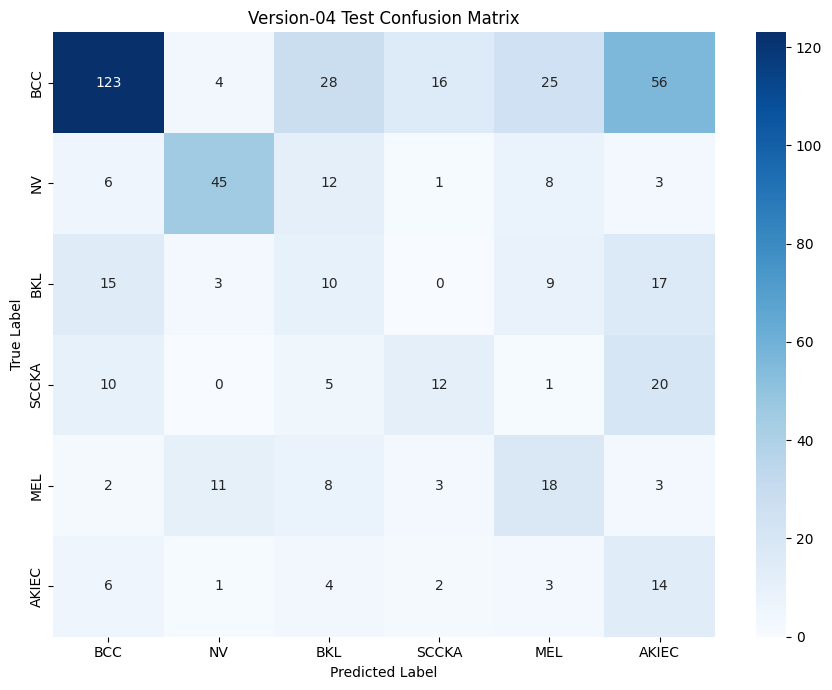

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Version-04 Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [36]:
from collections import Counter
import pandas as pd

actual_counts = Counter(all_labels)
predicted_counts = Counter(all_predictions)

distribution_df = pd.DataFrame({
    "Class": class_names,
    "Actual Test Samples": [
        actual_counts[i] for i in range(len(class_names))
    ],
    "Predicted Samples": [
        predicted_counts[i] for i in range(len(class_names))
    ]
})

distribution_df["Prediction Difference"] = (
    distribution_df["Predicted Samples"] -
    distribution_df["Actual Test Samples"]
)

print(distribution_df.to_string(index=False))

Class  Actual Test Samples  Predicted Samples  Prediction Difference
  BCC                  252                162                    -90
   NV                   75                 64                    -11
  BKL                   54                 67                     13
SCCKA                   48                 34                    -14
  MEL                   45                 64                     19
AKIEC                   30                113                     83


In [38]:
print("========== FOCAL LOSS DETAILS ==========")

print("Loss class:", type(criterion))
print("Loss configuration:", criterion)

print("\n========== INTERNAL PARAMETERS ==========")

for name, value in vars(criterion).items():
    if torch.is_tensor(value):
        print(f"{name}: {value.detach().cpu()}")
    else:
        print(f"{name}: {value}")

print("\n========== CLASS-WISE ALPHA ==========")

for name, weight in zip(
    class_names,
    criterion.alpha.detach().cpu().numpy()
):
    print(f"{name}: {weight:.4f}")

print("\nGamma:", criterion.gamma)

========== FOCAL LOSS DETAILS ==========
Loss class: <class '__main__.FocalLoss'>
Loss configuration: FocalLoss()

========== INTERNAL PARAMETERS ==========
training: True
_parameters: {}
_buffers: {'alpha': tensor([0.2120, 0.7166, 0.9835, 1.1318, 1.1884, 1.7678], device='cuda:0')}
_non_persistent_buffers_set: set()
_backward_pre_hooks: OrderedDict()
_backward_hooks: OrderedDict()
_is_full_backward_hook: None
_forward_hooks: OrderedDict()
_forward_hooks_with_kwargs: OrderedDict()
_forward_hooks_always_called: OrderedDict()
_forward_pre_hooks: OrderedDict()
_forward_pre_hooks_with_kwargs: OrderedDict()
_state_dict_hooks: OrderedDict()
_state_dict_pre_hooks: OrderedDict()
_load_state_dict_pre_hooks: OrderedDict()
_load_state_dict_post_hooks: OrderedDict()
_modules: {}
gamma: 2.0

========== CLASS-WISE ALPHA ==========
BCC: 0.2120
NV: 0.7166
BKL: 0.9835
SCCKA: 1.1318
MEL: 1.1884
AKIEC: 1.7678

Gamma: 2.0


In [39]:
for i, cell in enumerate(In):
    if "class FocalLoss" in cell:
        print(f"Found FocalLoss definition in cell {i}:")
        print(cell)
        break
else:
    print("FocalLoss definition not found in notebook history.")

Found FocalLoss definition in cell 19:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.gamma = gamma

        if alpha is not None:
            self.register_buffer("alpha", alpha)
        else:
            self.alpha = None

    def forward(self, inputs, targets):

        log_probs = torch.nn.functional.log_softmax(
            inputs, dim=1
        )

        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)

        pt = log_pt.exp()

        focal_factor = (1.0 - pt) ** self.gamma

        loss = -focal_factor * log_pt

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            loss = alpha_t * loss

        return loss.mean()


criterion = FocalLoss(
    alpha=alpha,
    gamma=GAMMA
).to(device)

print("Loss:", criterion.__class__.__name__)
print("Gamma:", criterion.gamma)
print("Alpha:", criterion.alpha)


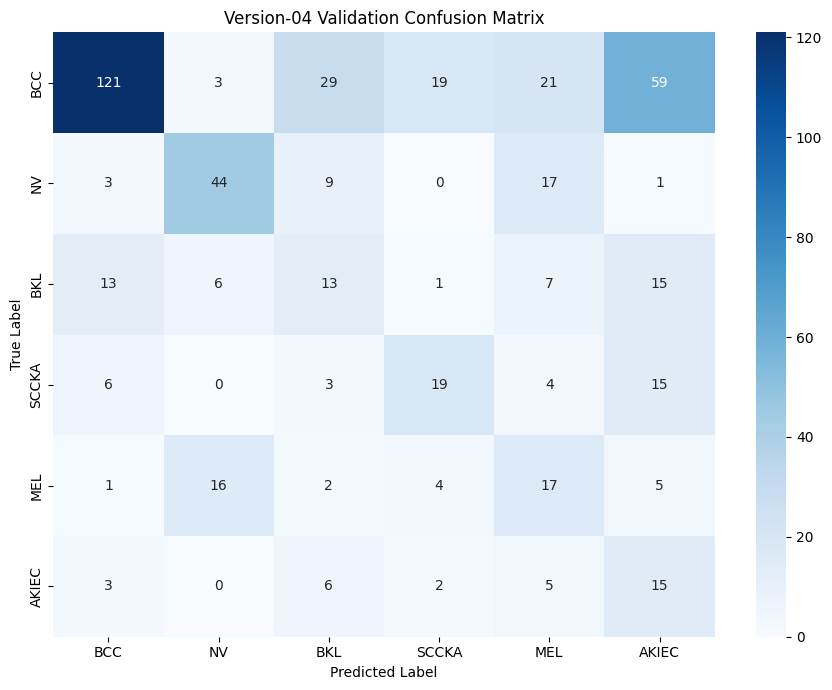


Validation Classification Report:

              precision    recall  f1-score   support

         BCC       0.82      0.48      0.61       252
          NV       0.64      0.59      0.62        74
         BKL       0.21      0.24      0.22        55
       SCCKA       0.42      0.40      0.41        47
         MEL       0.24      0.38      0.29        45
       AKIEC       0.14      0.48      0.21        31

    accuracy                           0.45       504
   macro avg       0.41      0.43      0.39       504
weighted avg       0.60      0.45      0.50       504



In [40]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()

val_labels = []
val_predictions = []

with torch.no_grad():

    for clinical, dermoscopic, labels in val_loader:

        clinical = clinical.to(device)
        dermoscopic = dermoscopic.to(device)

        outputs = model(clinical, dermoscopic)
        predictions = outputs.argmax(dim=1)

        val_labels.extend(labels.cpu().numpy())
        val_predictions.extend(predictions.cpu().numpy())

        functional.reset_net(model)

# Validation confusion matrix
val_cm = confusion_matrix(
    val_labels,
    val_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    val_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Version-04 Validation Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nValidation Classification Report:\n")

print(classification_report(
    val_labels,
    val_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

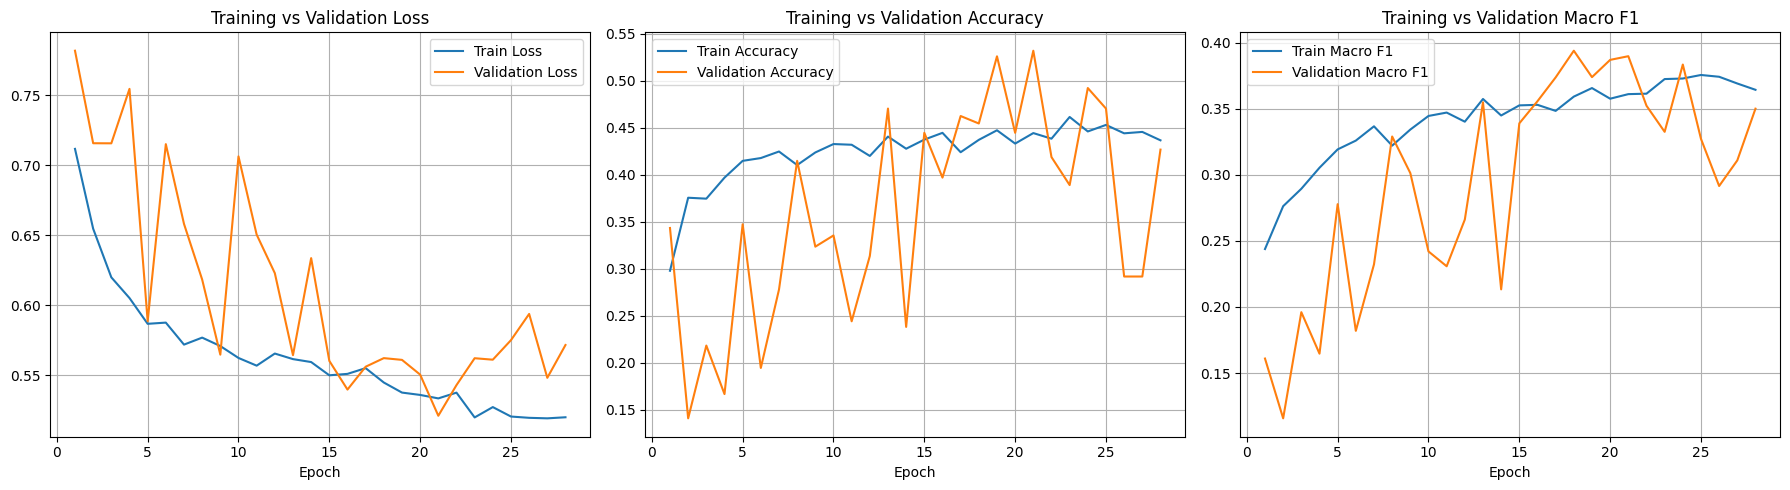

In [43]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(epochs_range, history["train_acc"], label="Train Accuracy")
axes[1].plot(epochs_range, history["val_acc"], label="Validation Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

# Macro F1
axes[2].plot(epochs_range, history["train_f1"], label="Train Macro F1")
axes[2].plot(epochs_range, history["val_f1"], label="Validation Macro F1")
axes[2].set_title("Training vs Validation Macro F1")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()